In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
})

BLUE, RED, GREEN, GREY = "#2E6FBE", "#D1495B", "#2A9D8F", "#8A8A8A"
print("Libraries ready:",
      "pandas", pd.__version__, "| numpy", np.__version__)

Libraries ready: pandas 2.2.2 | numpy 2.0.2


In [2]:
%%writefile generate_data.py


import numpy as np
import pandas as pd


#  Reproducibility

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)


#  Configuration

START_DATE = "2024-01-01"
N_DAYS = 120                     # ~4 months of hourly data
FREQ = "h"

# Merchant catalogue: (id, display name, baseline hourly volume, sector)
MERCHANTS = [
    ("M001", "Aurora Apparel",      55,  "Retail/Fashion"),
    ("M002", "ByteBox Software",     30,  "Digital/SaaS"),
    ("M003", "Crave Food Delivery",  90,  "Food Delivery"),
    ("M004", "DriftTravel",          22,  "Travel"),
    ("M005", "EverGreen Grocers",    70,  "Grocery"),
]

# Average authorisation (approval) rate per merchant under normal conditions.
BASE_AUTH_RATE = {
    "M001": 0.93, "M002": 0.90, "M003": 0.95, "M004": 0.88, "M005": 0.96
}

# Log-normal parameters (in log space) for the per-transaction value (in EUR).
# mu, sigma chosen so that median ticket sizes look sensible per sector.
TICKET_PARAMS = {
    "M001": (3.7, 0.5),
    "M002": (3.0, 0.7),
    "M003": (2.9, 0.4),
    "M004": (5.5, 0.6),
    "M005": (3.3, 0.4),
}



#  Seasonality profiles

def intraday_profile(hour: int) -> float:

    # A smooth double-bump curve built from two Gaussians (lunch + evening).
    lunch = np.exp(-0.5 * ((hour - 13) / 3.0) ** 2)
    evening = np.exp(-0.5 * ((hour - 20) / 2.5) ** 2)
    night_floor = 0.15
    raw = night_floor + 0.9 * lunch + 1.0 * evening
    return raw


def weekly_profile(dayofweek: int) -> float:

    # Retail-style week: busier Fri-Sun, quieter mid-week.
    profile = {0: 0.95, 1: 0.92, 2: 0.94, 3: 1.00, 4: 1.12, 5: 1.25, 6: 1.18}
    return profile[dayofweek]


# Pre-compute a normalisation so the intraday factors average to 1.0.
_INTRADAY_MEAN = np.mean([intraday_profile(h) for h in range(24)])



#  Core series construction

def build_merchant_series(mid: str, base_volume: float,
                          index: pd.DatetimeIndex) -> pd.DataFrame:

    n = len(index)

    hours = index.hour.to_numpy()
    dows = index.dayofweek.to_numpy()

    intraday = np.array([intraday_profile(h) for h in hours]) / _INTRADAY_MEAN
    weekly = np.array([weekly_profile(d) for d in dows])

    # Slow linear growth: +25% over the whole window.
    t = np.arange(n) / n
    trend = 1.0 + 0.25 * t

    # Expected hourly transaction rate (lambda for the Poisson draw).
    expected = base_volume * intraday * weekly * trend
    expected = np.clip(expected, 0.5, None)

    # Poisson count noise around the expected rate.
    counts = rng.poisson(expected).astype(float)

    df = pd.DataFrame(
        {
            "timestamp": index,
            "merchant_id": mid,
            "expected_volume": expected,
            "txn_count": counts,
        }
    )
    return df


def attach_value_and_auth(df: pd.DataFrame, mid: str) -> pd.DataFrame:

    mu, sigma = TICKET_PARAMS[mid]
    auth_rate = BASE_AUTH_RATE[mid]

    total_value = np.zeros(len(df))
    auth_count = np.zeros(len(df))

    counts = df["txn_count"].to_numpy().astype(int)
    for i, c in enumerate(counts):
        if c <= 0:
            continue
        # Per-transaction monetary value (log-normal), summed for the hour.
        values = rng.lognormal(mean=mu, sigma=sigma, size=c)
        total_value[i] = values.sum()
        # Authorisation outcomes (binomial around the merchant base rate).
        auth_count[i] = rng.binomial(c, auth_rate)

    df = df.copy()
    df["total_value"] = np.round(total_value, 2)
    df["auth_count"] = auth_count.astype(int)
    return df


#  Anomaly injection

def _window_mask(index, start, length_hours):
    start_ts = pd.Timestamp(start)
    end_ts = start_ts + pd.Timedelta(hours=length_hours)
    return (index >= start_ts) & (index < end_ts)


def inject_anomalies(df: pd.DataFrame, mid: str) -> pd.DataFrame:

    df = df.copy()
    df["is_anomaly"] = 0
    df["anomaly_type"] = ""
    index = df["timestamp"]

    # A small per-merchant schedule of events. Times are chosen to fall on
    # different days so they do not overlap.
    schedule = {
        "M001": [
            ("2024-01-20 10:00", 8,  "SPIKE", 4.0),     # flash sale
            ("2024-02-14 00:00", 14, "DROP",  0.15),    # checkout outage
            ("2024-03-05 09:00", 10, "AUTH_DROP", None),# acquirer issue
        ],
        "M002": [
            ("2024-02-02 03:00", 6,  "SPIKE", 6.0),     # card-testing attack
            ("2024-03-18 08:00", 18, "DROP",  0.10),    # API outage
        ],
        "M003": [
            ("2024-01-28 18:00", 5,  "SPIKE", 3.5),     # promo / event
            ("2024-02-25 12:00", 12, "AUTH_DROP", None),# BIN routing fault
        ],
        "M004": [
            ("2024-02-10 06:00", 9,  "DROP",  0.12),    # gateway outage
            ("2024-03-22 11:00", 7,  "SPIKE", 5.0),     # fare sale
        ],
        "M005": [
            ("2024-01-15 16:00", 6,  "SPIKE", 3.0),
            ("2024-03-12 07:00", 16, "DROP",  0.20),
        ],
    }

    for start, length, atype, magnitude in schedule.get(mid, []):
        mask = _window_mask(index, start, length).to_numpy()
        if not mask.any():
            continue

        if atype == "SPIKE":
            df.loc[mask, "txn_count"] = (
                df.loc[mask, "txn_count"] * magnitude
            ).round().astype(int)
            # Re-derive value & auth for the affected hours.
            mu, sigma = TICKET_PARAMS[mid]
            for i in np.where(mask)[0]:
                c = int(df.iloc[i]["txn_count"])
                vals = rng.lognormal(mu, sigma, size=max(c, 0))
                df.iat[i, df.columns.get_loc("total_value")] = round(vals.sum(), 2)
                df.iat[i, df.columns.get_loc("auth_count")] = int(
                    rng.binomial(c, BASE_AUTH_RATE[mid])
                )

        elif atype == "DROP":
            df.loc[mask, "txn_count"] = (
                df.loc[mask, "txn_count"] * magnitude
            ).round().astype(int)
            for i in np.where(mask)[0]:
                c = int(df.iloc[i]["txn_count"])
                mu, sigma = TICKET_PARAMS[mid]
                vals = rng.lognormal(mu, sigma, size=max(c, 0))
                df.iat[i, df.columns.get_loc("total_value")] = round(vals.sum(), 2)
                df.iat[i, df.columns.get_loc("auth_count")] = int(
                    rng.binomial(c, BASE_AUTH_RATE[mid])
                )

        elif atype == "AUTH_DROP":
            # Volume looks normal; authorisation rate collapses to ~30%.
            for i in np.where(mask)[0]:
                c = int(df.iloc[i]["txn_count"])
                df.iat[i, df.columns.get_loc("auth_count")] = int(
                    rng.binomial(c, 0.30)
                )

        df.loc[mask, "is_anomaly"] = 1
        df.loc[mask, "anomaly_type"] = atype

    return df



#  Public entry point

def generate_dataset() -> pd.DataFrame:
    """Generate the full multi-merchant dataset and return a tidy dataframe."""
    index = pd.date_range(start=START_DATE, periods=N_DAYS * 24, freq=FREQ)

    frames = []
    for mid, name, base, sector in MERCHANTS:
        s = build_merchant_series(mid, base, index)
        s = attach_value_and_auth(s, mid)
        s = inject_anomalies(s, mid)
        s["merchant_name"] = name
        s["sector"] = sector
        frames.append(s)

    data = pd.concat(frames, ignore_index=True)

    # Derived fields useful downstream.
    data["auth_rate"] = np.where(
        data["txn_count"] > 0, data["auth_count"] / data["txn_count"], np.nan
    )
    data["avg_ticket"] = np.where(
        data["txn_count"] > 0, data["total_value"] / data["txn_count"], np.nan
    )

    # Tidy column order.
    cols = [
        "timestamp", "merchant_id", "merchant_name", "sector",
        "txn_count", "total_value", "auth_count", "auth_rate", "avg_ticket",
        "is_anomaly", "anomaly_type",
    ]
    data = data[cols].sort_values(["merchant_id", "timestamp"]).reset_index(drop=True)
    return data


if __name__ == "__main__":
    df = generate_dataset()
    out = "synthetic_transactions.csv"
    df.to_csv(out, index=False)
    print(f"Generated {len(df):,} rows for {df['merchant_id'].nunique()} merchants.")
    print(f"Date range: {df['timestamp'].min()} -> {df['timestamp'].max()}")
    print(f"Injected anomaly rows: {int(df['is_anomaly'].sum()):,} "
          f"({100*df['is_anomaly'].mean():.2f}% of data)")
    print(f"Saved to {out}")
    print(df.head())

Writing generate_data.py


In [3]:
%%writefile anomaly_detection.py

from __future__ import annotations

import numpy as np
import pandas as pd
from dataclasses import dataclass, field
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler



#  Small statistical helpers

def mad(x: np.ndarray) -> float:

    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    if x.size == 0:
        return 0.0
    med = np.median(x)
    return 1.4826 * np.median(np.abs(x - med))


def robust_z(x: np.ndarray) -> np.ndarray:

    x = np.asarray(x, dtype=float)
    med = np.nanmedian(x)
    scale = mad(x)
    if scale == 0:
        scale = np.nanstd(x) if np.nanstd(x) > 0 else 1.0
    return (x - med) / scale



#  Configuration object

@dataclass
class DetectorConfig:

    z_threshold: float = 4.0          # robust z-score alert threshold
    rolling_window_days: int = 14     # window for adaptive decomposition
    roll_threshold: float = 4.0       # threshold on rolling residual score
    iforest_contamination: float = 0.015
    iforest_estimators: int = 300
    auth_drop_z: float = 3.5          # threshold for authorisation collapse
    ensemble_min_votes: int = 2       # votes required to raise a flag
    random_state: int = 42



#  Method 1 - Seasonal robust z-score

def seasonal_robust_zscore(df: pd.DataFrame, value_col: str,
                           cfg: DetectorConfig) -> pd.Series:

    work = df.copy()
    work["dow"] = work["timestamp"].dt.dayofweek
    work["hour"] = work["timestamp"].dt.hour

    scores = pd.Series(index=work.index, dtype=float)
    for (_, _), grp in work.groupby(["dow", "hour"]):
        scores.loc[grp.index] = robust_z(grp[value_col].to_numpy())
    return scores



#  Method 2 - Rolling seasonal decomposition

def rolling_decomposition_score(df: pd.DataFrame, value_col: str,
                                cfg: DetectorConfig) -> pd.Series:

    s = df.sort_values("timestamp").reset_index()
    series = s[value_col].astype(float)

    # --- trend: 25-hour centred rolling median (captures the daily centre) ---
    trend = series.rolling(window=25, center=True, min_periods=6).median()
    detrended = series - trend

    # --- seasonality: median detrended value per (dow, hour) ---
    s["dow"] = s["timestamp"].dt.dayofweek
    s["hour"] = s["timestamp"].dt.hour
    s["_detrended"] = detrended
    seasonal = s.groupby(["dow", "hour"])["_detrended"].transform("median")

    resid = detrended - seasonal

    # --- adaptive standardisation with a trailing window ---
    win = cfg.rolling_window_days * 24
    roll_med = resid.rolling(window=win, min_periods=win // 3).median()
    roll_scale = resid.rolling(window=win, min_periods=win // 3).apply(
        lambda a: mad(a), raw=True
    )
    roll_scale = roll_scale.replace(0, np.nan).fillna(resid.std() or 1.0)

    score = (resid - roll_med) / roll_scale
    # Map back to the original (unsorted) index.
    out = pd.Series(index=df.index, dtype=float)
    out.loc[s["index"].to_numpy()] = score.to_numpy()
    return out



#  Method 3 - Isolation Forest on engineered features

def isolation_forest_score(df: pd.DataFrame, cfg: DetectorConfig) -> pd.Series:

    work = df.copy()
    work["hour"] = work["timestamp"].dt.hour
    work["dow"] = work["timestamp"].dt.dayofweek

    # Deseasonalise volume and value so the model sees deviations, not season.
    vol_z = seasonal_robust_zscore(work, "txn_count", cfg)
    val_z = seasonal_robust_zscore(work, "total_value", cfg)

    feats = pd.DataFrame({
        "vol_z": vol_z,
        "val_z": val_z,
        "auth_rate": work["auth_rate"].fillna(work["auth_rate"].median()),
        "avg_ticket": work["avg_ticket"].fillna(work["avg_ticket"].median()),
        "hour_sin": np.sin(2 * np.pi * work["hour"] / 24),
        "hour_cos": np.cos(2 * np.pi * work["hour"] / 24),
        "dow": work["dow"],
    }).fillna(0.0)

    X = StandardScaler().fit_transform(feats)
    model = IsolationForest(
        n_estimators=cfg.iforest_estimators,
        contamination=cfg.iforest_contamination,
        random_state=cfg.random_state,
        n_jobs=-1,
    )
    model.fit(X)
    # decision_function: higher = more normal. Invert and min-max to [0,1].
    raw = -model.decision_function(X)
    rng = raw.max() - raw.min()
    norm = (raw - raw.min()) / rng if rng > 0 else np.zeros_like(raw)
    return pd.Series(norm, index=df.index)



#  Authorisation-rate collapse detector

def auth_collapse_score(df: pd.DataFrame, cfg: DetectorConfig) -> pd.Series:

    z = seasonal_robust_zscore(df, "auth_rate", cfg)
    # We only care about the downside (auth rate falling).
    return (-z).clip(lower=0)



#  Ensemble orchestration

@dataclass
class AnomalyResult:

    scored: pd.DataFrame
    alerts: pd.DataFrame
    config: DetectorConfig = field(default_factory=DetectorConfig)


def detect(df: pd.DataFrame, cfg: DetectorConfig | None = None) -> AnomalyResult:

    cfg = cfg or DetectorConfig()
    df = df.sort_values("timestamp").reset_index(drop=True).copy()

    # --- individual scores ------------------------------------------------- #
    df["score_z"] = seasonal_robust_zscore(df, "txn_count", cfg)
    df["score_roll"] = rolling_decomposition_score(df, "txn_count", cfg)
    df["score_iforest"] = isolation_forest_score(df, cfg)
    df["score_auth"] = auth_collapse_score(df, cfg)

    # --- per-method binary votes ------------------------------------------- #
    df["vote_z"] = (df["score_z"].abs() >= cfg.z_threshold).astype(int)
    df["vote_roll"] = (df["score_roll"].abs() >= cfg.roll_threshold).astype(int)
    iforest_cut = df["score_iforest"].quantile(1 - cfg.iforest_contamination)
    df["vote_iforest"] = (df["score_iforest"] >= iforest_cut).astype(int)
    df["vote_auth"] = (df["score_auth"] >= cfg.auth_drop_z).astype(int)

    # --- ensemble decision ------------------------------------------------- #
    df["votes"] = df[["vote_z", "vote_roll", "vote_iforest"]].sum(axis=1)
    df["is_flagged"] = (
        (df["votes"] >= cfg.ensemble_min_votes) | (df["vote_auth"] == 1)
    ).astype(int)

    # --- direction / type classification ----------------------------------- #
    def classify(row):
        if row["vote_auth"] == 1 and row["votes"] < cfg.ensemble_min_votes:
            return "AUTH_DROP"
        if row["is_flagged"]:
            if row["score_z"] > 0 or row["score_roll"] > 0:
                return "SPIKE"
            return "DROP"
        return ""
    df["predicted_type"] = df.apply(classify, axis=1)

    # --- severity score (0-100) for ranking alerts ------------------------- #
    sev = (
        df["score_z"].abs().fillna(0) * 0.35
        + df["score_roll"].abs().fillna(0) * 0.35
        + df["score_iforest"].fillna(0) * 10 * 0.15
        + df["score_auth"].fillna(0) * 0.15
    )
    sev = (sev / sev.max() * 100) if sev.max() > 0 else sev
    df["severity"] = sev.round(1)

    alerts = (
        df[df["is_flagged"] == 1]
        .sort_values("severity", ascending=False)
        [["timestamp", "merchant_id", "txn_count", "total_value",
          "auth_rate", "predicted_type", "severity", "votes",
          "score_z", "score_roll", "score_iforest", "score_auth"]]
        .reset_index(drop=True)
    )

    return AnomalyResult(scored=df, alerts=alerts, config=cfg)


def detect_portfolio(df: pd.DataFrame,
                     cfg: DetectorConfig | None = None) -> AnomalyResult:
    """Convenience wrapper that runs `detect` for every merchant and stitches
    the results back together."""
    cfg = cfg or DetectorConfig()
    scored_frames, alert_frames = [], []
    for mid, grp in df.groupby("merchant_id"):
        res = detect(grp, cfg)
        scored_frames.append(res.scored)
        alert_frames.append(res.alerts)
    scored = pd.concat(scored_frames, ignore_index=True)
    alerts = pd.concat(alert_frames, ignore_index=True).sort_values(
        "severity", ascending=False).reset_index(drop=True)
    return AnomalyResult(scored=scored, alerts=alerts, config=cfg)

Writing anomaly_detection.py


In [4]:
%%writefile evaluation.py

from __future__ import annotations
import numpy as np
import pandas as pd


def point_metrics(scored: pd.DataFrame) -> dict:

    y_true = scored["is_anomaly"].to_numpy().astype(int)
    y_pred = scored["is_flagged"].to_numpy().astype(int)

    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())

    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = (2 * precision * recall / (precision + recall)
          if (precision + recall) else 0.0)
    accuracy = (tp + tn) / len(y_true)

    return {
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "precision": round(precision, 3),
        "recall": round(recall, 3),
        "f1": round(f1, 3),
        "accuracy": round(accuracy, 4),
    }


def _label_events(mask: np.ndarray) -> list[tuple[int, int]]:

    events = []
    in_run = False
    start = 0
    for i, v in enumerate(mask):
        if v and not in_run:
            in_run, start = True, i
        elif not v and in_run:
            in_run = False
            events.append((start, i - 1))
    if in_run:
        events.append((start, len(mask) - 1))
    return events


def event_metrics(scored: pd.DataFrame) -> dict:

    df = scored.sort_values(["merchant_id", "timestamp"]).reset_index(drop=True)
    detected, total = 0, 0
    detection_delays = []

    for _, grp in df.groupby("merchant_id"):
        truth = grp["is_anomaly"].to_numpy().astype(bool)
        pred = grp["is_flagged"].to_numpy().astype(bool)
        for (s, e) in _label_events(truth):
            total += 1
            window_pred = pred[s:e + 1]
            if window_pred.any():
                detected += 1
                # Delay = hours from event start to first detection.
                first = np.argmax(window_pred)
                detection_delays.append(int(first))

    recall_event = detected / total if total else 0.0
    mean_delay = float(np.mean(detection_delays)) if detection_delays else np.nan
    return {
        "events_total": total,
        "events_detected": detected,
        "event_recall": round(recall_event, 3),
        "mean_detection_delay_hours": round(mean_delay, 2),
    }


def per_type_recall(scored: pd.DataFrame) -> pd.DataFrame:
    """Event-level recall broken down by anomaly type."""
    df = scored.sort_values(["merchant_id", "timestamp"]).reset_index(drop=True)
    rows = []
    for atype in ["SPIKE", "DROP", "AUTH_DROP"]:
        total, detected = 0, 0
        for _, grp in df.groupby("merchant_id"):
            truth = (grp["anomaly_type"] == atype).to_numpy()
            pred = grp["is_flagged"].to_numpy().astype(bool)
            for (s, e) in _label_events(truth):
                total += 1
                if pred[s:e + 1].any():
                    detected += 1
        rows.append({
            "anomaly_type": atype,
            "events": total,
            "detected": detected,
            "recall": round(detected / total, 3) if total else np.nan,
        })
    return pd.DataFrame(rows)


def method_agreement(scored: pd.DataFrame) -> pd.DataFrame:
    """Per-method point recall, to show each detector's individual
    contribution to the ensemble."""
    y = scored["is_anomaly"].to_numpy().astype(bool)
    rows = []
    for col, name in [("vote_z", "Robust z-score"),
                      ("vote_roll", "Rolling decomposition"),
                      ("vote_iforest", "Isolation Forest"),
                      ("vote_auth", "Auth-collapse"),
                      ("is_flagged", "Ensemble (final)")]:
        pred = scored[col].to_numpy().astype(bool)
        tp = int((y & pred).sum())
        fp = int((~y & pred).sum())
        fn = int((y & ~pred).sum())
        prec = tp / (tp + fp) if (tp + fp) else 0.0
        rec = tp / (tp + fn) if (tp + fn) else 0.0
        f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
        rows.append({
            "method": name,
            "precision": round(prec, 3),
            "recall": round(rec, 3),
            "f1": round(f1, 3),
        })
    return pd.DataFrame(rows)

Writing evaluation.py


In [5]:
!python generate_data.py

Generated 14,400 rows for 5 merchants.
Date range: 2024-01-01 00:00:00 -> 2024-04-29 23:00:00
Injected anomaly rows: 111 (0.77% of data)
Saved to synthetic_transactions.csv
            timestamp merchant_id  ... is_anomaly anomaly_type
0 2024-01-01 00:00:00        M001  ...          0             
1 2024-01-01 01:00:00        M001  ...          0             
2 2024-01-01 02:00:00        M001  ...          0             
3 2024-01-01 03:00:00        M001  ...          0             
4 2024-01-01 04:00:00        M001  ...          0             

[5 rows x 11 columns]


In [6]:

df = pd.read_csv("synthetic_transactions.csv", parse_dates=["timestamp"])

table1 = (df.groupby(["merchant_id", "merchant_name", "sector"])
            .agg(hours=("txn_count", "size"),
                 total_txns=("txn_count", "sum"),
                 mean_per_hour=("txn_count", "mean"),
                 mean_auth=("auth_rate", "mean"),
                 anomaly_hours=("is_anomaly", "sum"))
            .round({"mean_per_hour": 1, "mean_auth": 3})
            .reset_index())

print("TABLE 1 — Synthetic dataset summary")
print("=" * 78)
display(table1)
print(f"\nTotal rows         : {len(df):,}")
print(f"Total transactions : {int(df.txn_count.sum()):,}")
print(f"Total value (EUR)  : {df.total_value.sum():,.2f}")
print(f"Anomalous hours    : {int(df.is_anomaly.sum())} "
      f"({100*df.is_anomaly.mean():.2f}% of data)")

TABLE 1 — Synthetic dataset summary


,merchant_id,merchant_name,sector,hours,total_txns,mean_per_hour,mean_auth,anomaly_hours
0,M001,Aurora Apparel,Retail/Fashion,2880,188620.0,65.5,0.928,32
1,M002,ByteBox Software,Digital/SaaS,2880,101888.0,35.4,0.900,24
2,M003,Crave Food Delivery,Food Delivery,2880,308849.0,107.2,0.947,17
3,M004,DriftTravel,Travel,2880,76108.0,26.4,0.883,16
4,M005,EverGreen Grocers,Grocery,2880,238637.0,82.9,0.960,22



Total rows         : 14,400
Total transactions : 914,102
Total value (EUR)  : 46,657,940.74
Anomalous hours    : 111 (0.77% of data)


In [7]:
from anomaly_detection import detect_portfolio, DetectorConfig
from evaluation import (point_metrics, event_metrics,
                        per_type_recall, method_agreement)

cfg = DetectorConfig()                 # default thresholds (z = 4.0, etc.)
res = detect_portfolio(df, cfg)
scored = res.scored                    # per-row scores, votes, flags
print("Detection complete.")
print(f"Rows scored: {len(scored):,} | Hours flagged: {int(scored.is_flagged.sum())}")

Detection complete.
Rows scored: 14,400 | Hours flagged: 249


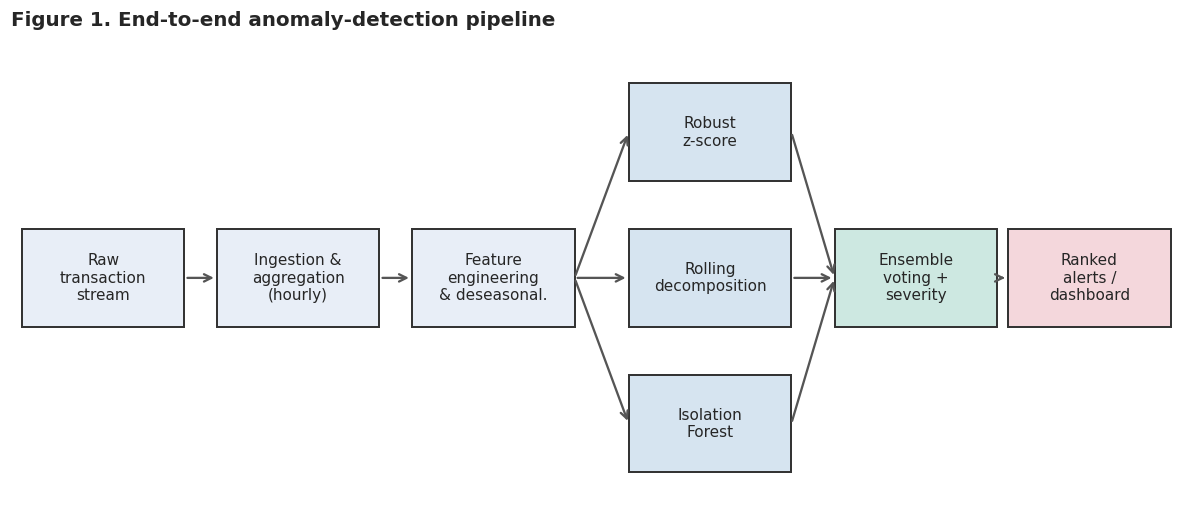

In [8]:
def figure1_architecture():
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.axis("off")

    def box(x, y, text, color, w=0.15, h=0.20):
        ax.add_patch(plt.Rectangle((x, y), w, h, facecolor=color,
                     edgecolor="#333", lw=1.3, zorder=2))
        ax.text(x + w/2, y + h/2, text, ha="center", va="center",
                fontsize=10, zorder=3)
        return (x, y, w, h)

    c = {}
    c["raw"]  = box(0.01, 0.40, "Raw\ntransaction\nstream", "#E8EEF7")
    c["ing"]  = box(0.19, 0.40, "Ingestion &\naggregation\n(hourly)", "#E8EEF7")
    c["feat"] = box(0.37, 0.40, "Feature\nengineering\n& deseasonal.", "#E8EEF7")
    c["z"]    = box(0.57, 0.70, "Robust\nz-score", "#D6E4F0")
    c["roll"] = box(0.57, 0.40, "Rolling\ndecomposition", "#D6E4F0")
    c["if"]   = box(0.57, 0.10, "Isolation\nForest", "#D6E4F0")
    c["ens"]  = box(0.76, 0.40, "Ensemble\nvoting +\nseverity", "#CDE8E1")
    c["out"]  = box(0.92, 0.40, "Ranked\nalerts /\ndashboard", "#F4D7DC")

    def arrow(a, b):
        ax1, ay, aw, ah = a; bx, by, bw, bh = b
        ax.annotate("", xy=(bx, by + bh/2), xytext=(ax1 + aw, ay + ah/2),
                    arrowprops=dict(arrowstyle="->", color="#555", lw=1.5))

    arrow(c["raw"], c["ing"]); arrow(c["ing"], c["feat"])
    for k in ["z", "roll", "if"]:
        arrow(c["feat"], c[k]); arrow(c[k], c["ens"])
    arrow(c["ens"], c["out"])

    ax.set_xlim(0, 1.08); ax.set_ylim(0, 1)
    ax.set_title("Figure 1. End-to-end anomaly-detection pipeline", loc="left")
    plt.tight_layout(); plt.show()

figure1_architecture()

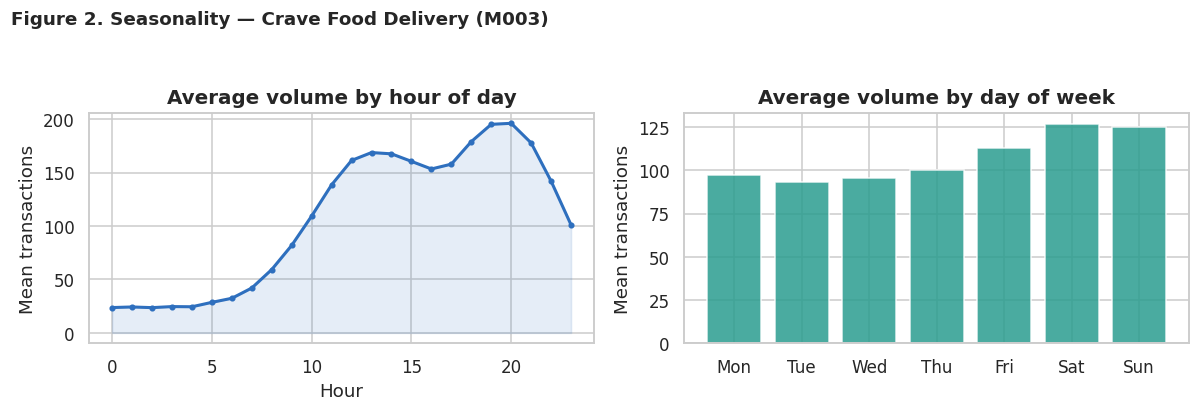

In [9]:
def figure2_seasonality(merchant_id="M003"):
    m = df[df["merchant_id"] == merchant_id].copy()
    m["hour"] = m["timestamp"].dt.hour
    m["dow"]  = m["timestamp"].dt.dayofweek
    name = m["merchant_name"].iloc[0]

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

    hourly = m.groupby("hour")["txn_count"].mean()
    axes[0].plot(hourly.index, hourly.values, color=BLUE, lw=2, marker="o", ms=3)
    axes[0].fill_between(hourly.index, hourly.values, alpha=0.12, color=BLUE)
    axes[0].set(title="Average volume by hour of day",
                xlabel="Hour", ylabel="Mean transactions")

    days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
    weekly = m.groupby("dow")["txn_count"].mean()
    axes[1].bar([days[i] for i in weekly.index], weekly.values,
                color=GREEN, alpha=0.85)
    axes[1].set(title="Average volume by day of week", ylabel="Mean transactions")

    fig.suptitle(f"Figure 2. Seasonality — {name} ({merchant_id})",
                 x=0.01, ha="left", fontsize=12, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.93]); plt.show()

figure2_seasonality()

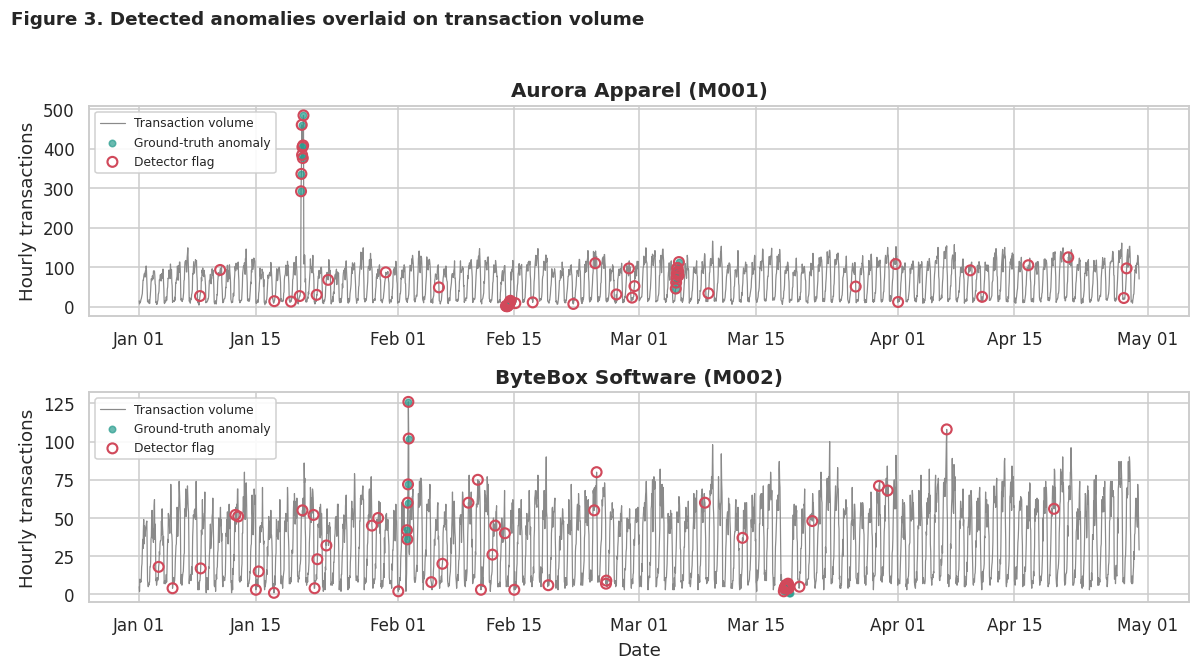

In [10]:
def figure3_timeseries(merchants=("M001", "M002")):
    fig, axes = plt.subplots(len(merchants), 1, figsize=(11, 3.1*len(merchants)))
    if len(merchants) == 1:
        axes = [axes]
    for ax, mid in zip(axes, merchants):
        m = scored[scored["merchant_id"] == mid].sort_values("timestamp")
        name = m["merchant_name"].iloc[0]
        ax.plot(m["timestamp"], m["txn_count"], color=GREY, lw=0.8,
                label="Transaction volume")
        truth = m[m["is_anomaly"] == 1]
        flagged = m[m["is_flagged"] == 1]
        ax.scatter(truth["timestamp"], truth["txn_count"], s=18, color=GREEN,
                   label="Ground-truth anomaly", zorder=3, alpha=0.7)
        ax.scatter(flagged["timestamp"], flagged["txn_count"], s=42,
                   facecolors="none", edgecolors=RED, lw=1.4,
                   label="Detector flag", zorder=4)
        ax.set(title=f"{name} ({mid})", ylabel="Hourly transactions")
        ax.legend(loc="upper left", fontsize=8, framealpha=0.9)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    axes[-1].set_xlabel("Date")
    fig.suptitle("Figure 3. Detected anomalies overlaid on transaction volume",
                 x=0.01, ha="left", fontsize=12, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

figure3_timeseries()

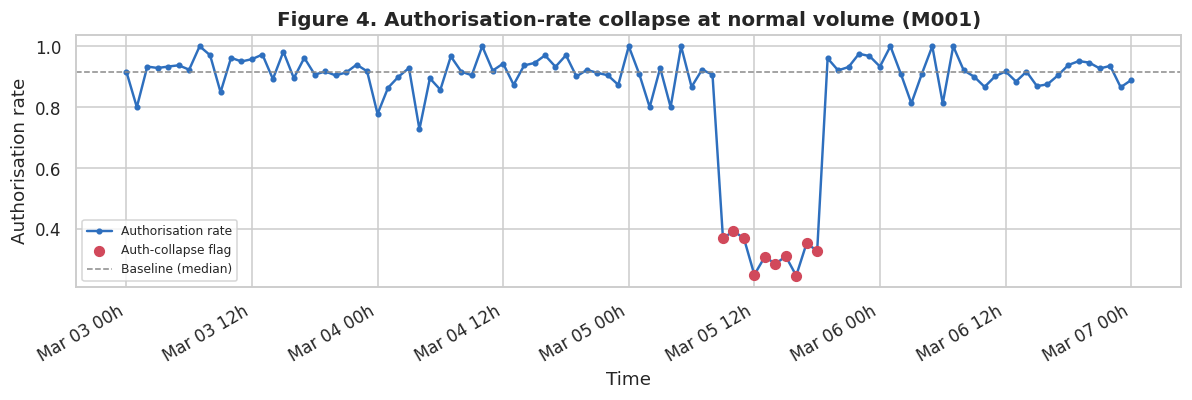

In [11]:
def figure4_authdrop(merchant_id="M001", start="2024-03-03", end="2024-03-07"):
    m = scored[scored["merchant_id"] == merchant_id].sort_values("timestamp")
    w = m[(m["timestamp"] >= start) & (m["timestamp"] <= end)]

    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.plot(w["timestamp"], w["auth_rate"], color=BLUE, lw=1.6, marker="o",
            ms=3, label="Authorisation rate")
    flag = w[w["vote_auth"] == 1]
    ax.scatter(flag["timestamp"], flag["auth_rate"], color=RED, s=40, zorder=4,
               label="Auth-collapse flag")
    ax.axhline(w["auth_rate"].median(), color=GREY, ls="--", lw=1,
               label="Baseline (median)")
    ax.set(title=f"Figure 4. Authorisation-rate collapse at normal volume ({merchant_id})",
           ylabel="Authorisation rate", xlabel="Time")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d %Hh"))
    ax.legend(loc="lower left", fontsize=8)
    fig.autofmt_xdate(rotation=30)
    plt.tight_layout(); plt.show()

figure4_authdrop()

In [12]:
pm = point_metrics(scored)
em = event_metrics(scored)

table2 = pd.DataFrame([
    ["Event recall",          f"{em['event_recall']:.3f}",            "All incidents detected"],
    ["Mean detection delay",  f"{em['mean_detection_delay_hours']:.2f} h", "Flagged within the first hour"],
    ["Point recall",          f"{pm['recall']:.3f}",                  "Most anomalous hours caught"],
    ["Point precision",       f"{pm['precision']:.3f}",               "Flags per true anomalous hour"],
    ["Point F1",              f"{pm['f1']:.3f}",                      "Balanced point-level score"],
    ["Accuracy",              f"{pm['accuracy']:.4f}",                "On a <1% anomaly base rate"],
], columns=["Metric", "Value", "Interpretation"])

print("TABLE 2 — Headline performance")
print("=" * 70)
display(table2)

TABLE 2 — Headline performance


,Metric,Value,Interpretation
0,Event recall,1.000,All incidents detected
1,Mean detection delay,0.55 h,Flagged within the first hour
2,Point recall,0.865,Most anomalous hours caught
3,Point precision,0.386,Flags per true anomalous hour
4,Point F1,0.533,Balanced point-level score
5,Accuracy,0.9883,On a <1% anomaly base rate


In [13]:
table3 = per_type_recall(scored)
print("TABLE 3 — Event-level recall by anomaly type")
print("=" * 70)
display(table3)

TABLE 3 — Event-level recall by anomaly type


,anomaly_type,events,detected,recall
0,SPIKE,5,5,1.0
1,DROP,4,4,1.0
2,AUTH_DROP,2,2,1.0


TABLE 4 — Point-level performance by method


,method,precision,recall,f1
0,Robust z-score,0.507,0.667,0.576
1,Rolling decomposition,0.336,0.396,0.364
2,Isolation Forest,0.409,0.811,0.544
3,Auth-collapse,0.160,0.225,0.187
4,Ensemble (final),0.386,0.865,0.533


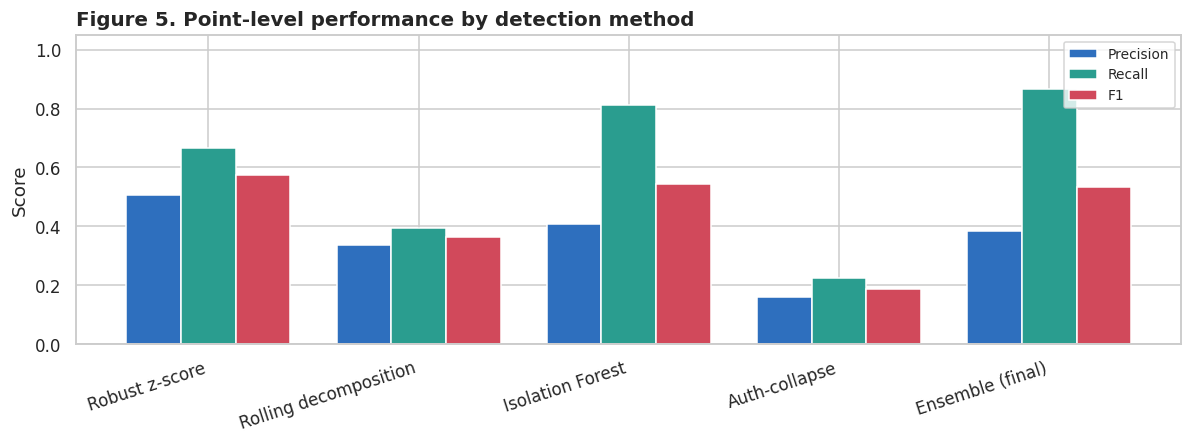

In [14]:
table4 = method_agreement(scored)
print("TABLE 4 — Point-level performance by method")
print("=" * 70)
display(table4)

def figure5_methods(ma):
    fig, ax = plt.subplots(figsize=(11, 4.2))
    x = np.arange(len(ma)); w = 0.26
    ax.bar(x - w, ma["precision"], w, label="Precision", color=BLUE)
    ax.bar(x,     ma["recall"],    w, label="Recall",    color=GREEN)
    ax.bar(x + w, ma["f1"],        w, label="F1",        color=RED)
    ax.set_xticks(x); ax.set_xticklabels(ma["method"], rotation=18, ha="right")
    ax.set_ylim(0, 1.05); ax.set_ylabel("Score")
    ax.set_title("Figure 5. Point-level performance by detection method", loc="left")
    ax.legend(loc="upper right", fontsize=9)
    plt.tight_layout(); plt.show()

figure5_methods(table4)

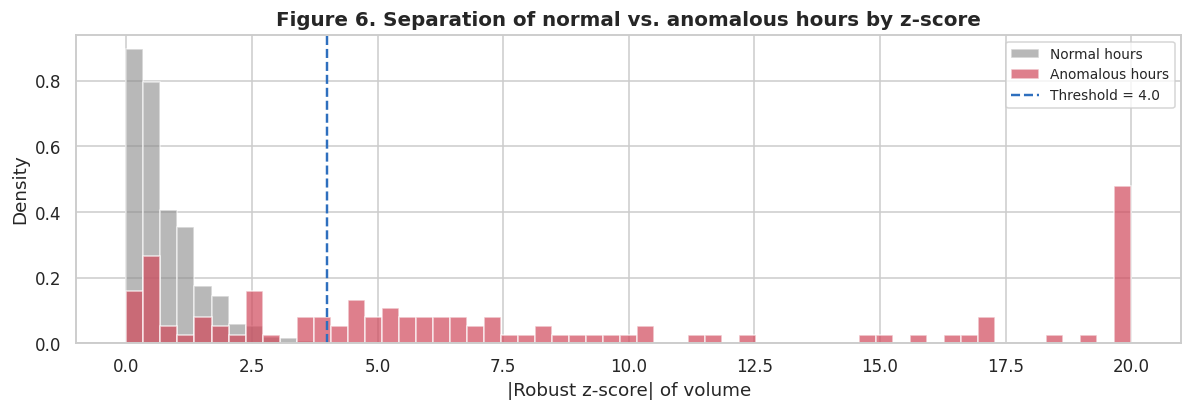

In [15]:
def figure6_separation():
    normal = scored[scored["is_anomaly"] == 0]["score_z"].abs()
    anom   = scored[scored["is_anomaly"] == 1]["score_z"].abs()
    bins = np.linspace(0, 20, 60)

    fig, ax = plt.subplots(figsize=(11, 3.9))
    ax.hist(normal.clip(upper=20), bins=bins, alpha=0.6, color=GREY,
            label="Normal hours", density=True)
    ax.hist(anom.clip(upper=20), bins=bins, alpha=0.7, color=RED,
            label="Anomalous hours", density=True)
    ax.axvline(cfg.z_threshold, color=BLUE, ls="--", lw=1.6,
               label=f"Threshold = {cfg.z_threshold}")
    ax.set(xlabel="|Robust z-score| of volume", ylabel="Density",
           title="Figure 6. Separation of normal vs. anomalous hours by z-score")
    ax.legend(fontsize=9)
    plt.tight_layout(); plt.show()

figure6_separation()

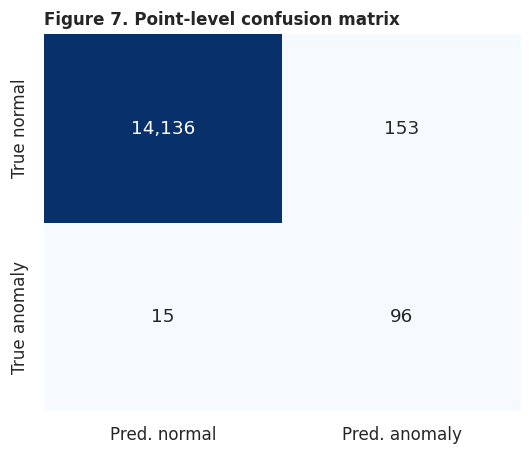

In [16]:
def figure7_confusion():
    cm = np.array([[pm["TN"], pm["FP"]],
                   [pm["FN"], pm["TP"]]])
    fig, ax = plt.subplots(figsize=(5, 4.3))
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
                xticklabels=["Pred. normal", "Pred. anomaly"],
                yticklabels=["True normal", "True anomaly"], ax=ax,
                annot_kws={"fontsize": 12})
    ax.set_title("Figure 7. Point-level confusion matrix", loc="left", fontsize=11)
    plt.tight_layout(); plt.show()

figure7_confusion()

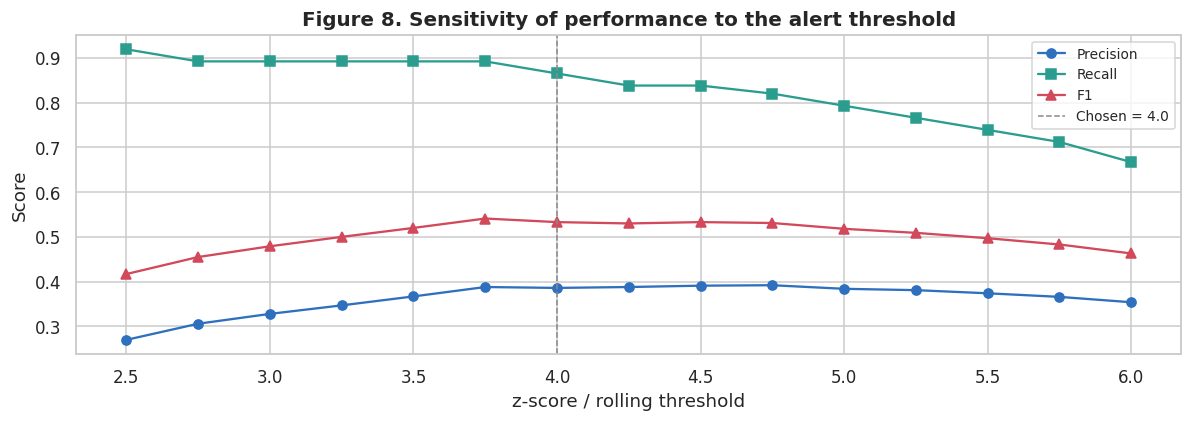

Event-level recall across the swept range: min=1.000, max=1.000 (stays at 100% throughout)


In [17]:
def figure8_sensitivity():
    thresholds = np.arange(2.5, 6.1, 0.25)
    precs, recs, f1s, ev_recs = [], [], [], []
    for t in thresholds:
        c = DetectorConfig(z_threshold=t, roll_threshold=t)
        r = detect_portfolio(df, c)
        m = point_metrics(r.scored)
        precs.append(m["precision"]); recs.append(m["recall"]); f1s.append(m["f1"])
        ev_recs.append(event_metrics(r.scored)["event_recall"])

    fig, ax = plt.subplots(figsize=(11, 4.0))
    ax.plot(thresholds, precs, marker="o", color=BLUE,  label="Precision")
    ax.plot(thresholds, recs,  marker="s", color=GREEN, label="Recall")
    ax.plot(thresholds, f1s,   marker="^", color=RED,   label="F1")
    ax.axvline(cfg.z_threshold, color=GREY, ls="--", lw=1,
               label=f"Chosen = {cfg.z_threshold}")
    ax.set(xlabel="z-score / rolling threshold", ylabel="Score",
           title="Figure 8. Sensitivity of performance to the alert threshold")
    ax.legend(fontsize=9)
    plt.tight_layout(); plt.show()

    print(f"Event-level recall across the swept range: "
          f"min={min(ev_recs):.3f}, max={max(ev_recs):.3f} "
          f"(stays at 100% throughout)")

figure8_sensitivity()

In [18]:
alerts = res.alerts[["timestamp", "merchant_id", "txn_count", "total_value",
                     "auth_rate", "predicted_type", "severity", "votes"]]
print(f"Total alerts raised: {len(res.alerts)}  |  showing top 15 by severity")
print("=" * 70)
display(alerts.head(15))

Total alerts raised: 249  |  showing top 15 by severity


,timestamp,merchant_id,txn_count,total_value,auth_rate,predicted_type,severity,votes
0,2024-01-20 12:00:00,M001,460.0,21594.34,0.934783,SPIKE,100.0,3
1,2024-02-02 07:00:00,M002,126.0,3194.39,0.888889,SPIKE,100.0,3
2,2024-01-28 20:00:00,M003,738.0,14482.76,0.956640,SPIKE,100.0,3
3,2024-01-15 21:00:00,M005,354.0,10495.73,0.940678,SPIKE,100.0,3
4,2024-03-22 17:00:00,M004,255.0,72378.62,0.870588,SPIKE,100.0,3
5,2024-01-15 19:00:00,M005,381.0,11354.80,0.955381,SPIKE,100.0,3
6,2024-01-15 20:00:00,M005,372.0,11635.77,0.965054,SPIKE,99.7,3
7,2024-01-15 17:00:00,M005,297.0,8642.82,0.959596,SPIKE,97.1,3
8,2024-01-20 17:00:00,M001,484.0,21723.59,0.940083,SPIKE,93.6,3
9,2024-01-20 16:00:00,M001,408.0,18648.11,0.926471,SPIKE,85.9,3


In [19]:
cfg2 = DetectorConfig(z_threshold=3.0, roll_threshold=3.0)
res2 = detect_portfolio(df, cfg2)
print("Looser threshold (3.0):", point_metrics(res2.scored))
print("Event recall          :", event_metrics(res2.scored)["event_recall"])

Looser threshold (3.0): {'TP': 99, 'FP': 203, 'FN': 12, 'TN': 14086, 'precision': 0.328, 'recall': 0.892, 'f1': 0.479, 'accuracy': 0.9851}
Event recall          : 1.0
